In [ ]:
# Purpose:
#   Generate publication-ready cohort, metadata, and immune landscape figures
#   from the fully annotated PBMC scRNA-seq + imputed ADT dataset.
#
# Summary:
#   - Define plotting parameters (fonts, DPI, line widths)
#   - Load patient-level metadata and construct race–disease composite variables
#   - Summarize and test age distributions across race_stage groups
#   - Visualize patient metadata (disease state, age, diabetes, obesity) as row-annotated panels
#   - Load finalized, level-3–annotated PBMC AnnData object
#   - Define consistent color palettes for all immune cell subtypes
#   - Generate global and split UMAPs colored by immune cell identity and race_stage
#   - Quantify and export per-patient immune cell-type proportions
#   - Visualize PBMC composition across patients using stacked bar plots
#   - Assess QC metrics (gene count, UMI, mitochondrial %, Azimuth scores) by cell type
#   - Integrate imputed ADT expression into AnnData metadata
#   - Visualize protein markers across major immune lineages on UMAP
#   - Create shared legends and reusable visualization utilities for manuscript figures

# Header

In [1]:
from utils import *

In [2]:
from matplotlib.lines import Line2D

In [3]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [4]:
os.chdir('../')

# Meta data

In [4]:
color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'

}

binary_color = {'Y': 'navy', 'N': '#CCCCCC'}

In [5]:
meta = pd.read_csv('data/01_meta/meta_pt.csv')

# meta['race_stage'] = meta['race'] + '-' + meta['group']
# meta['race_stage'] = pd.Categorical(meta['race_stage'], categories=list(color_set.keys()), ordered=True)

# # Order by race_stage, then age
# meta = meta.sort_values(['race_stage', 'age'])

meta

,sampleid,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race_stage
0,9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
1,30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
2,36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
3,119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
4,28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
5,53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
6,77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
7,31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
8,6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
9,1-H,Pool137_10,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [6]:
pd.crosstab(
    meta['diabetes'],
    meta['obesity']
)

obesity,N,Y
diabetes,,
N,27,19
Y,4,5


In [10]:
# pip install tableone  # if needed

from tableone import TableOne
import pandas as pd
import numpy as np
from scipy import stats

meta2 = meta[['race_stage','age']].copy()
meta2 = meta2.dropna(subset=['race_stage', 'age'])
meta2['race_stage'] = meta2['race_stage'].astype(str)
meta2['age'] = pd.to_numeric(meta2['age'], errors='coerce')

print(meta2.shape)

# Summary: mean±sd and median[IQR] by group
tab = meta2.groupby('race_stage')['age'].agg(
    n='count',
    mean='mean',
    sd='std',
    median='median',
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
).reset_index()

tab['mean (sd)'] = tab.apply(lambda r: f"{r['mean']:.1f} ({r['sd']:.1f})", axis=1)
tab['median [IQR]'] = tab.apply(lambda r: f"{r['median']:.1f} [{r['q1']:.1f}, {r['q3']:.1f}]", axis=1)

tab_out = tab[['race_stage', 'n', 'mean (sd)', 'median [IQR]']]

# Test difference across race_stage groups (Kruskal-Wallis is safe)
groups = [g['age'].dropna().values for _, g in meta2.groupby('race_stage')]
# H, p = stats.kruskal(*groups)

print(tab_out.to_string(index=False))
# print(f"\nKruskal–Wallis p-value for age across race_stage: {p:.3g}")

from scipy.stats import f_oneway

F, p_anova = f_oneway(*groups)
print(f"ANOVA p-value: {p_anova:.3g}")

(55, 2)
race_stage  n   mean (sd)      median [IQR]
    NHB-BC 13 55.6 (18.1) 54.0 [45.0, 69.0]
  NHB-DCIS  4 54.2 (18.1) 49.0 [43.5, 59.8]
   NHB-HRL 10  57.0 (8.8) 59.9 [49.8, 62.9]
    NHW-BC 12 57.5 (14.3) 64.5 [45.5, 67.0]
  NHW-DCIS  6 53.2 (14.9) 49.0 [44.2, 59.8]
   NHW-HRL 10  55.3 (9.6) 58.7 [46.1, 60.3]
ANOVA p-value: 0.991


In [11]:
Counter(meta['race_stage'])

Counter({'NHB-BC': 13,
         'NHW-BC': 12,
         'NHW-HRL': 10,
         'NHB-HRL': 10,
         'NHW-DCIS': 6,
         'NHB-DCIS': 4})

In [12]:
meta['age'].describe()

count    55.000000
mean     55.850909
std      13.540035
min      31.000000
25%      44.750000
50%      57.700000
75%      64.950000
max      86.000000
Name: age, dtype: float64

In [13]:
meta.groupby(['diabetes','obesity']).size()

diabetes  obesity
N         N          27
          Y          19
Y         N           4
          Y           5
dtype: int64

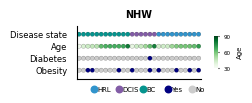

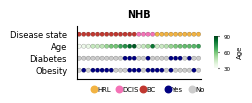

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --------------------
# Split data
# --------------------
meta_nhw = meta[meta['race'] == 'NHW'].sort_values(['race_stage', 'age'])
meta_nhb = meta[meta['race'] == 'NHB'].sort_values(['race_stage', 'age'])

# --------------------
# Row color builder
# --------------------
def make_rows(meta_sub):
    race_colors = meta_sub['race_stage'].map(color_set)
    age_colors = sns.color_palette("Greens", as_cmap=True)(
        (meta_sub['age'] - 30) / 60
    )
    diabetes_colors = meta_sub['diabetes'].map(binary_color)
    obesity_colors  = meta_sub['obesity'].map(binary_color)
    return [race_colors, age_colors, diabetes_colors, obesity_colors]

# --------------------
# Plot function (single panel)
# --------------------
def plot_meta_panel(meta_sub, race, fname):
    rows = make_rows(meta_sub)
    yticks = ['Obesity', 'Diabetes', 'Age', 'Disease state']

    fig, ax = plt.subplots(figsize=(1.6, .8))

    for i, row in enumerate(rows[::-1]):
        ax.scatter(
            np.arange(len(meta_sub)),
            [i] * len(meta_sub),
            c=row, s=10, edgecolors='k', linewidths=0.1
        )

    ax.set_yticks(range(4))
    ax.set_yticklabels(yticks, fontsize=6)
    ax.set_xlim(-0.5, len(meta_sub) - 0.5)
    ax.set_ylim(-0.7, 3.7)
    ax.set_xticks([])
    ax.set_title(race, fontsize=7, weight='bold')
    ax.tick_params(left=False, bottom=False)
    sns.despine(ax=ax)

    # age colorbar
    cax = inset_axes(ax, width="3%", height="60%", loc='center left',
                     bbox_to_anchor=(1.05, 0, 1, 1), bbox_transform=ax.transAxes)
    sm = plt.cm.ScalarMappable(cmap=plt.cm.Greens, norm=Normalize(30, 90))
    cb = plt.colorbar(sm, cax=cax)
    cb.set_ticks([30, 60, 90])
    cb.ax.tick_params(labelsize=4, length=1)
    cb.set_label('Age', fontsize=5)
    cb.outline.set_visible(False)

    # legend
    # stage_keys = [f'{race}-HRL', f'{race}-DCIS', f'{race}-BC']
    # labels = ['HRL', 'DCIS', 'BC', 'Yes', 'No']
    # colors = (
    #     [color_set[k] for k in stage_keys] +
    #     [binary_color['Y'], binary_color['N']]
    # )

    # lax = fig.add_axes([0.2, 0.04, 0.8, 0.10])
    # lax.axis('off')
    # spacing = 1.4
    # for i, (lab, col) in enumerate(zip(labels, colors)):
    #     x = i * spacing
    #     lax.scatter(x, 0, s=22, color=col)
    #     lax.text(x + 0.2, 0, lab, fontsize=5, va='center')
    # lax.set_xlim(-0.3, spacing * len(labels))

    # plt.savefig(fname, dpi=600, bbox_inches='tight')
    # plt.show()
# leave more bottom space for legend
    plt.subplots_adjust(bottom=0.22)
    
    # legend
    stage_keys = [f'{race}-HRL', f'{race}-DCIS', f'{race}-BC']
    labels = ['HRL', 'DCIS', 'BC', 'Yes', 'No']
    colors = (
        [color_set[k] for k in stage_keys] +
        [binary_color['Y'], binary_color['N']]
    )
    
    # y position controls distance from dotmap
    # larger second value = closer to dotmap
    # smaller second value = farther down
    lax = fig.add_axes([0.2, 0.04, 0.8, 0.10])
    lax.axis('off')
    
    spacing = 1.4
    for i, (lab, col) in enumerate(zip(labels, colors)):
        x = i * spacing
        lax.scatter(x, 0, s=22, color=col)
        lax.text(x + 0.2, 0, lab, fontsize=5, va='center')
    
    lax.set_xlim(-0.3, spacing * len(labels))
    lax.set_ylim(-0.5, 0.5)
    
    plt.savefig(fname, dpi=600, bbox_inches='tight')
    plt.show()

# --------------------
# Run separately
# --------------------
plot_meta_panel(meta_nhw, 'NHW', 'plots/F1/pt_meta_NHW.png')
plot_meta_panel(meta_nhb, 'NHB', 'plots/F1/pt_meta_NHB.png')

## Count per pt cell num

In [6]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)
dat

AnnData object with n_obs × n_vars = 434565 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standardized', 'vf_vst_counts.Pool137_11_variable', 'vf_vst_counts.Pool137

In [11]:
tmp = pd.crosstab(
    dat.obs['dataset_name'],
    dat.obs['celltype_level3']
)
tmp = tmp.reset_index()
tmp

celltype_level3,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Cytotoxic CD4T,Effector Memory CD4T,Treg,...,cDC1,cDC2,pDC,Classical Monocyte,Intermediate Monocyte,Nonclassical Monocyte,Cytotoxic Monocyte,CD56-dim NK,CD56-bright NK,Proliferating NK
0,Pool137_6,237,235,173,7,690,1117,11,169,95,...,2,68,41,1301,111,383,14,498,38,12
1,Pool137_7,403,679,167,6,1077,1195,11,294,109,...,4,68,40,1097,79,267,11,724,30,9
2,Pool137_8,766,767,291,6,828,2387,9,413,221,...,4,50,35,639,92,387,11,328,41,12
3,Pool137_9,598,125,50,4,979,1812,8,397,141,...,3,56,21,747,73,336,11,658,30,11
4,Pool137_10,134,58,27,6,1259,1579,12,162,86,...,10,144,45,1612,164,403,26,966,42,22
5,Pool137_11,172,139,103,12,2165,1253,11,207,153,...,5,124,58,1541,177,279,25,399,37,12
6,Pool137_12,138,35,38,4,259,310,12,46,33,...,3,67,38,1161,162,512,18,355,10,13
7,Pool137_14,643,342,107,13,1646,1891,20,258,222,...,1,106,53,1265,75,134,40,1057,87,14
8,Pool137_15,310,228,122,10,528,829,7,145,156,...,1,71,18,852,63,153,12,209,18,8
9,Pool137_16,366,312,191,27,814,1493,12,126,149,...,3,74,43,1186,122,351,24,365,24,2


In [9]:
meta

,sampleid,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race_stage
0,9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
1,30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
2,36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
3,119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
4,28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
5,53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
6,77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
7,31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
8,6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
9,1-H,Pool137_10,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [7]:
ST1 = pd.read_excel('data/Tables/ST1.xlsx')
ST1

,Patient ID,Race/Ethnicity,Disease State,Age at Diagnosis,Diabetes,Obesity,BMI (kg/m²)
0,43-H,NHW,HRL,42.5,N,Y,30.39
1,956-H,NHW,HRL,42.8,N,N,24.43
2,568-H,NHW,HRL,43.7,N,N,21.11
3,42-H,NHW,HRL,53.1,N,N,25.73
4,63-H,NHW,HRL,57.7,N,Y,34.10
5,36-H,NHW,HRL,59.6,N,N,27.98
6,61-H,NHW,HRL,59.6,N,N,25.09
7,24-H,NHW,HRL,60.5,N,Y,36.60
8,1-H,NHW,HRL,62.3,N,N,22.81
9,6-H,NHW,HRL,71.1,N,Y,34.13


In [12]:
mg = pd.merge(
    meta[['sampleid','dataset_name']],
    tmp,
    on = 'dataset_name'
)
mg

,sampleid,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Cytotoxic CD4T,Effector Memory CD4T,...,cDC1,cDC2,pDC,Classical Monocyte,Intermediate Monocyte,Nonclassical Monocyte,Cytotoxic Monocyte,CD56-dim NK,CD56-bright NK,Proliferating NK
0,9-D,Pool137_7,403,679,167,6,1077,1195,11,294,...,4,68,40,1097,79,267,11,724,30,9
1,30-D,Pool137_12,138,35,38,4,259,310,12,46,...,3,67,38,1161,162,512,18,355,10,13
2,36-D,Pool137_18,169,92,122,9,902,1277,34,390,...,10,107,24,1868,202,524,17,1063,77,12
3,119-D,Pool137_20,238,122,33,0,126,384,11,62,...,2,0,18,131,22,116,3,43,2,1
4,28-D,Pool137_24,581,91,69,21,1140,1240,12,265,...,10,91,72,2013,108,206,30,792,72,11
5,53-D,Pool137_27,309,134,86,7,740,795,16,135,...,2,24,17,879,108,247,21,228,14,0
6,77-D,Pool137_30,310,353,161,29,1668,1981,26,400,...,8,128,47,782,81,199,13,976,62,11
7,31-D,Pool138_6,488,263,59,2,655,1070,37,216,...,6,89,27,1671,142,177,103,111,22,3
8,6-H,Pool137_6,237,235,173,7,690,1117,11,169,...,2,68,41,1301,111,383,14,498,38,12
9,1-H,Pool137_10,134,58,27,6,1259,1579,12,162,...,10,144,45,1612,164,403,26,966,42,22


In [14]:
mgg = pd.merge(
    ST1, mg,
    left_on = 'Patient ID',
    right_on = 'sampleid',
    how = 'left'
)
mgg

,Patient ID,Race/Ethnicity,Disease State,Age at Diagnosis,Diabetes,Obesity,BMI (kg/m²),sampleid,dataset_name,Naive B,...,cDC1,cDC2,pDC,Classical Monocyte,Intermediate Monocyte,Nonclassical Monocyte,Cytotoxic Monocyte,CD56-dim NK,CD56-bright NK,Proliferating NK
0,43-H,NHW,HRL,42.5,N,Y,30.39,43-H,Pool137_14,643,...,1,106,53,1265,75,134,40,1057,87,14
1,956-H,NHW,HRL,42.8,N,N,24.43,956-H,Pool138_15,157,...,7,117,105,2766,215,647,30,480,87,8
2,568-H,NHW,HRL,43.7,N,N,21.11,568-H,Pool138_14,756,...,0,79,45,2068,189,334,10,590,65,16
3,42-H,NHW,HRL,53.1,N,N,25.73,42-H,Pool137_26,312,...,6,166,34,2756,225,298,33,587,74,5
4,63-H,NHW,HRL,57.7,N,Y,34.10,63-H,Pool138_9,552,...,5,85,51,1157,85,149,30,495,24,9
5,36-H,NHW,HRL,59.6,N,N,27.98,36-H,Pool137_25,170,...,3,184,59,1682,226,346,100,164,29,9
6,61-H,NHW,HRL,59.6,N,N,25.09,61-H,Pool137_29,470,...,11,256,61,2157,290,575,196,324,25,7
7,24-H,NHW,HRL,60.5,N,Y,36.60,24-H,Pool138_4,1017,...,23,168,51,1795,133,243,83,675,83,9
8,1-H,NHW,HRL,62.3,N,N,22.81,1-H,Pool137_10,134,...,10,144,45,1612,164,403,26,966,42,22
9,6-H,NHW,HRL,71.1,N,Y,34.13,6-H,Pool137_6,237,...,2,68,41,1301,111,383,14,498,38,12


In [15]:
mgg.to_csv('data/Tables/ST1_addedCellNumPerPt.csv')

In [16]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

labels = ["B", "T", "DC", "Mono", "NK"]
colors = ["#4C78C8", "#F58518", "#54A24B", "#E45756", "#9C8DC3"]  # B, T, DC, Mono, NK

handles = [Line2D([0], [0], marker='o', color='none',
                  markerfacecolor=c, markeredgecolor='none',
                  markersize=12, label=l)
           for l, c in zip(labels, colors)]

fig, ax = plt.subplots(figsize=(5, 0.6))
ax.axis("off")
ax.legend(handles=handles, loc="center", ncol=len(labels),
          frameon=False, handletextpad=0.3, columnspacing=1.2, fontsize=13)

fig.savefig("plots/Legends/celltype_legend.png", dpi=300, bbox_inches="tight", transparent=True)

# sc UMAP

In [28]:
tmp = dat.obs[['celltype_level3','dataset_name']].drop_duplicates()

Counter(tmp['celltype_level3'])

Counter({'Naive CD4T': 55,
         'Nonclassical Monocyte': 55,
         'CD56-dim NK': 55,
         'Naive B': 55,
         'Central Memory CD4T': 55,
         'Classical Monocyte': 55,
         'Cytotoxic Monocyte': 55,
         'Cytotoxic CD4T': 55,
         'Effector Memory CD4T': 55,
         'Intermediate Monocyte': 55,
         'Effector Memory CD8T': 55,
         'Treg': 55,
         'pDC': 55,
         'Mature B': 55,
         'Memory B': 55,
         'Central Memory CD8T': 55,
         'Naive CD8T': 54,
         'cDC2': 54,
         'CD56-bright NK': 54,
         'cDC1': 54,
         'Proliferating NK': 54,
         'Plasmablast': 53,
         'MAIT': 52,
         'Double Negative T': 46,
         'γδ T': 40})

In [9]:
print(len(dat.obs['dataset_name'].unique()))

55


In [43]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]



In [44]:
import colorcet as cc
import seaborn as sns

plt25 = sns.color_palette(cc.glasbey_bw_minc_20, n_colors=25)
sns.palplot(plt25)

In [45]:
celltype_palette = dict(zip(cells_ordered, plt25))

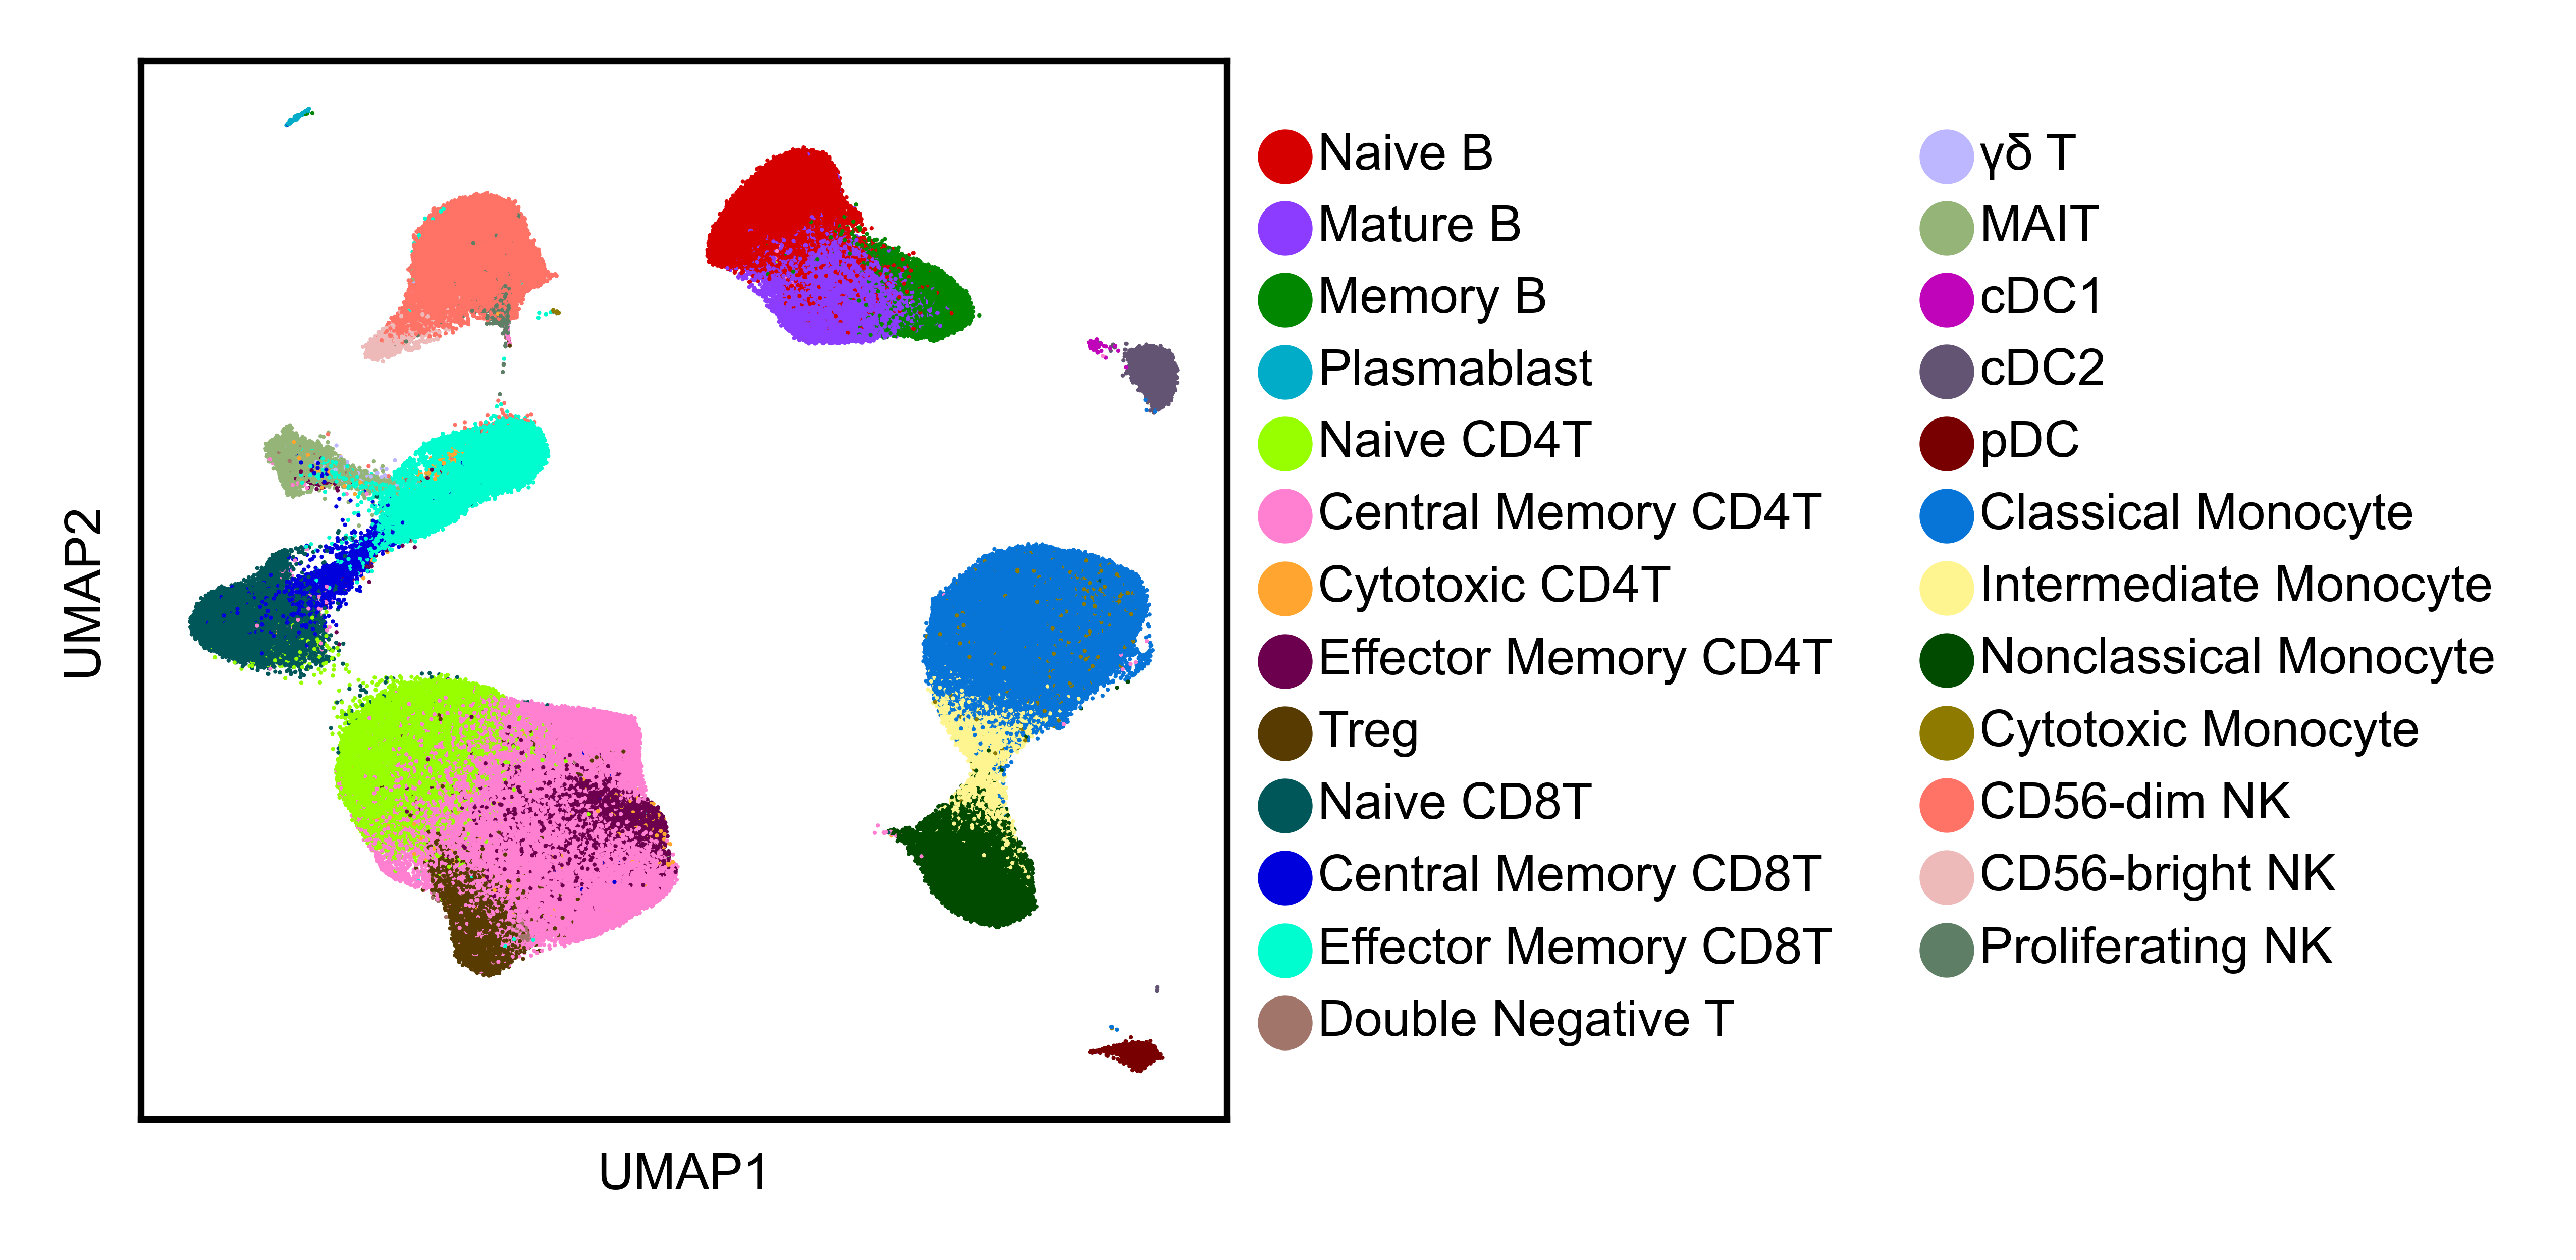

In [47]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/F1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})


palette = [celltype_palette[x] for x in dat.obs['celltype_level3'].cat.categories]

sc.settings._vector_friendly = True
with rc_context({"figure.figsize": (2.3, 2.3)}):
    
    sc.pl.umap(dat, color=['celltype_level3'], 
               title='',
               s=1, 
               frameon=True, 
               ncols=1, 
               palette = palette,
               save='celltype_level3.svg'
              )

# QC metrics

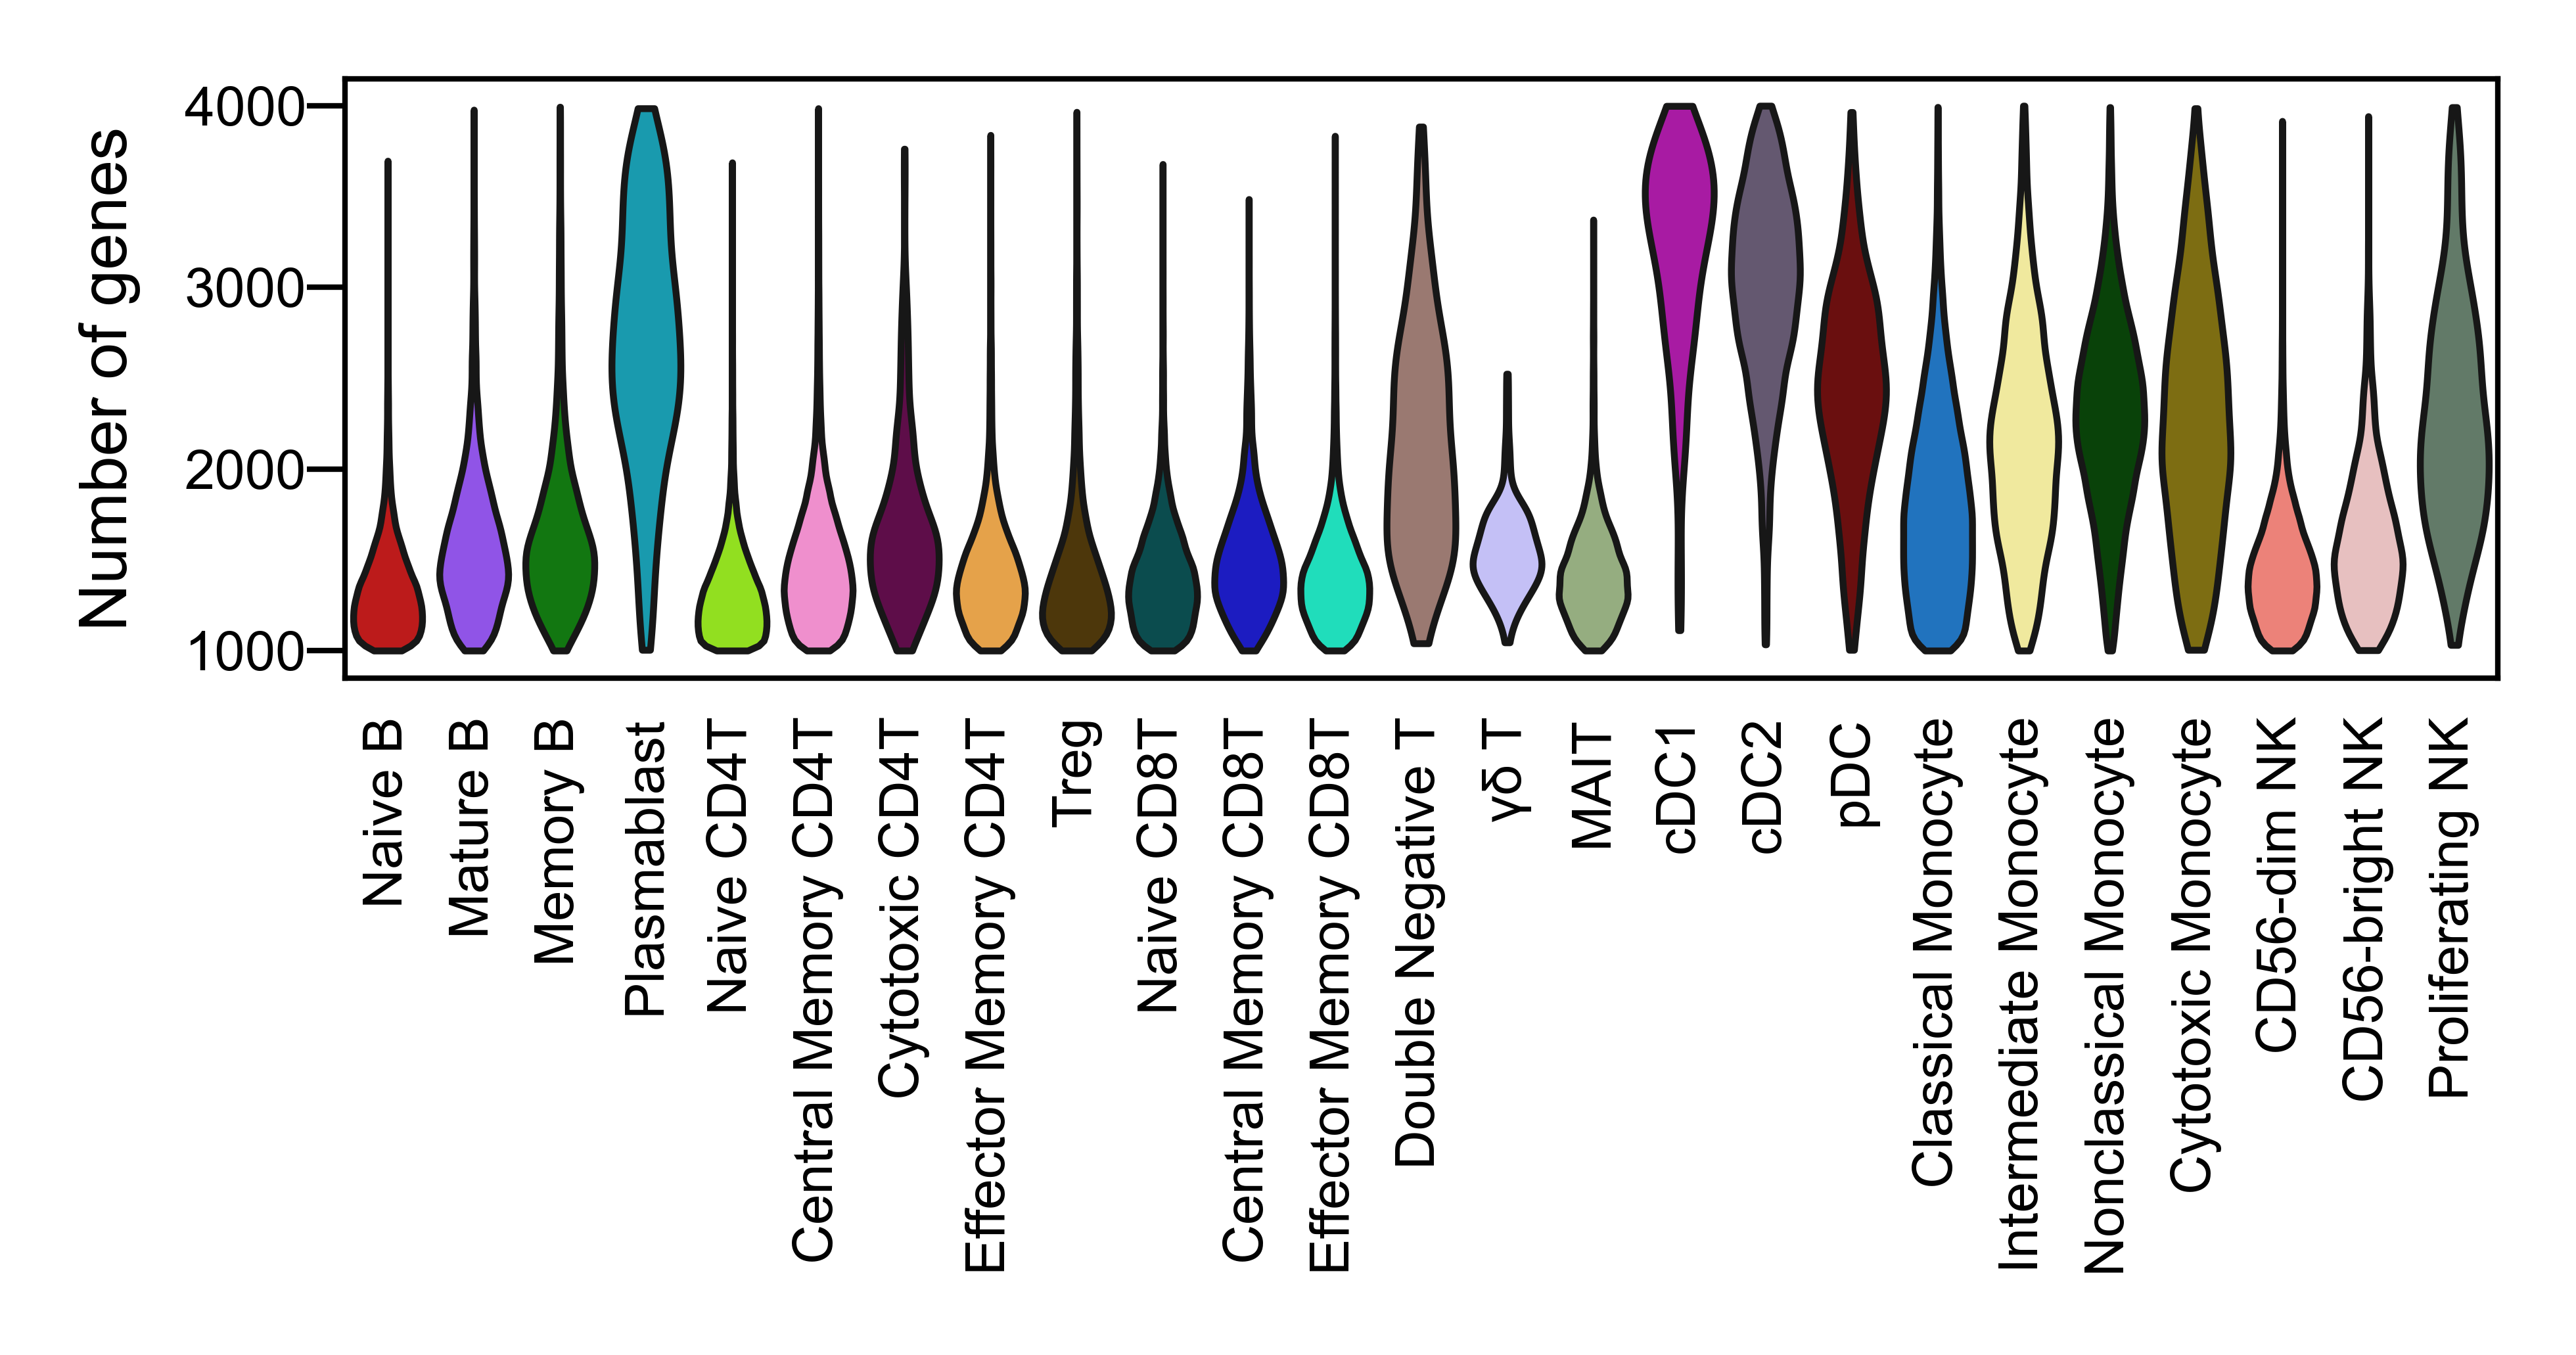

In [73]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['nFeature_RNA'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Number of genes',
    rotation=90,
    ax=ax,
    save='qc_NumGenes.svg'
)


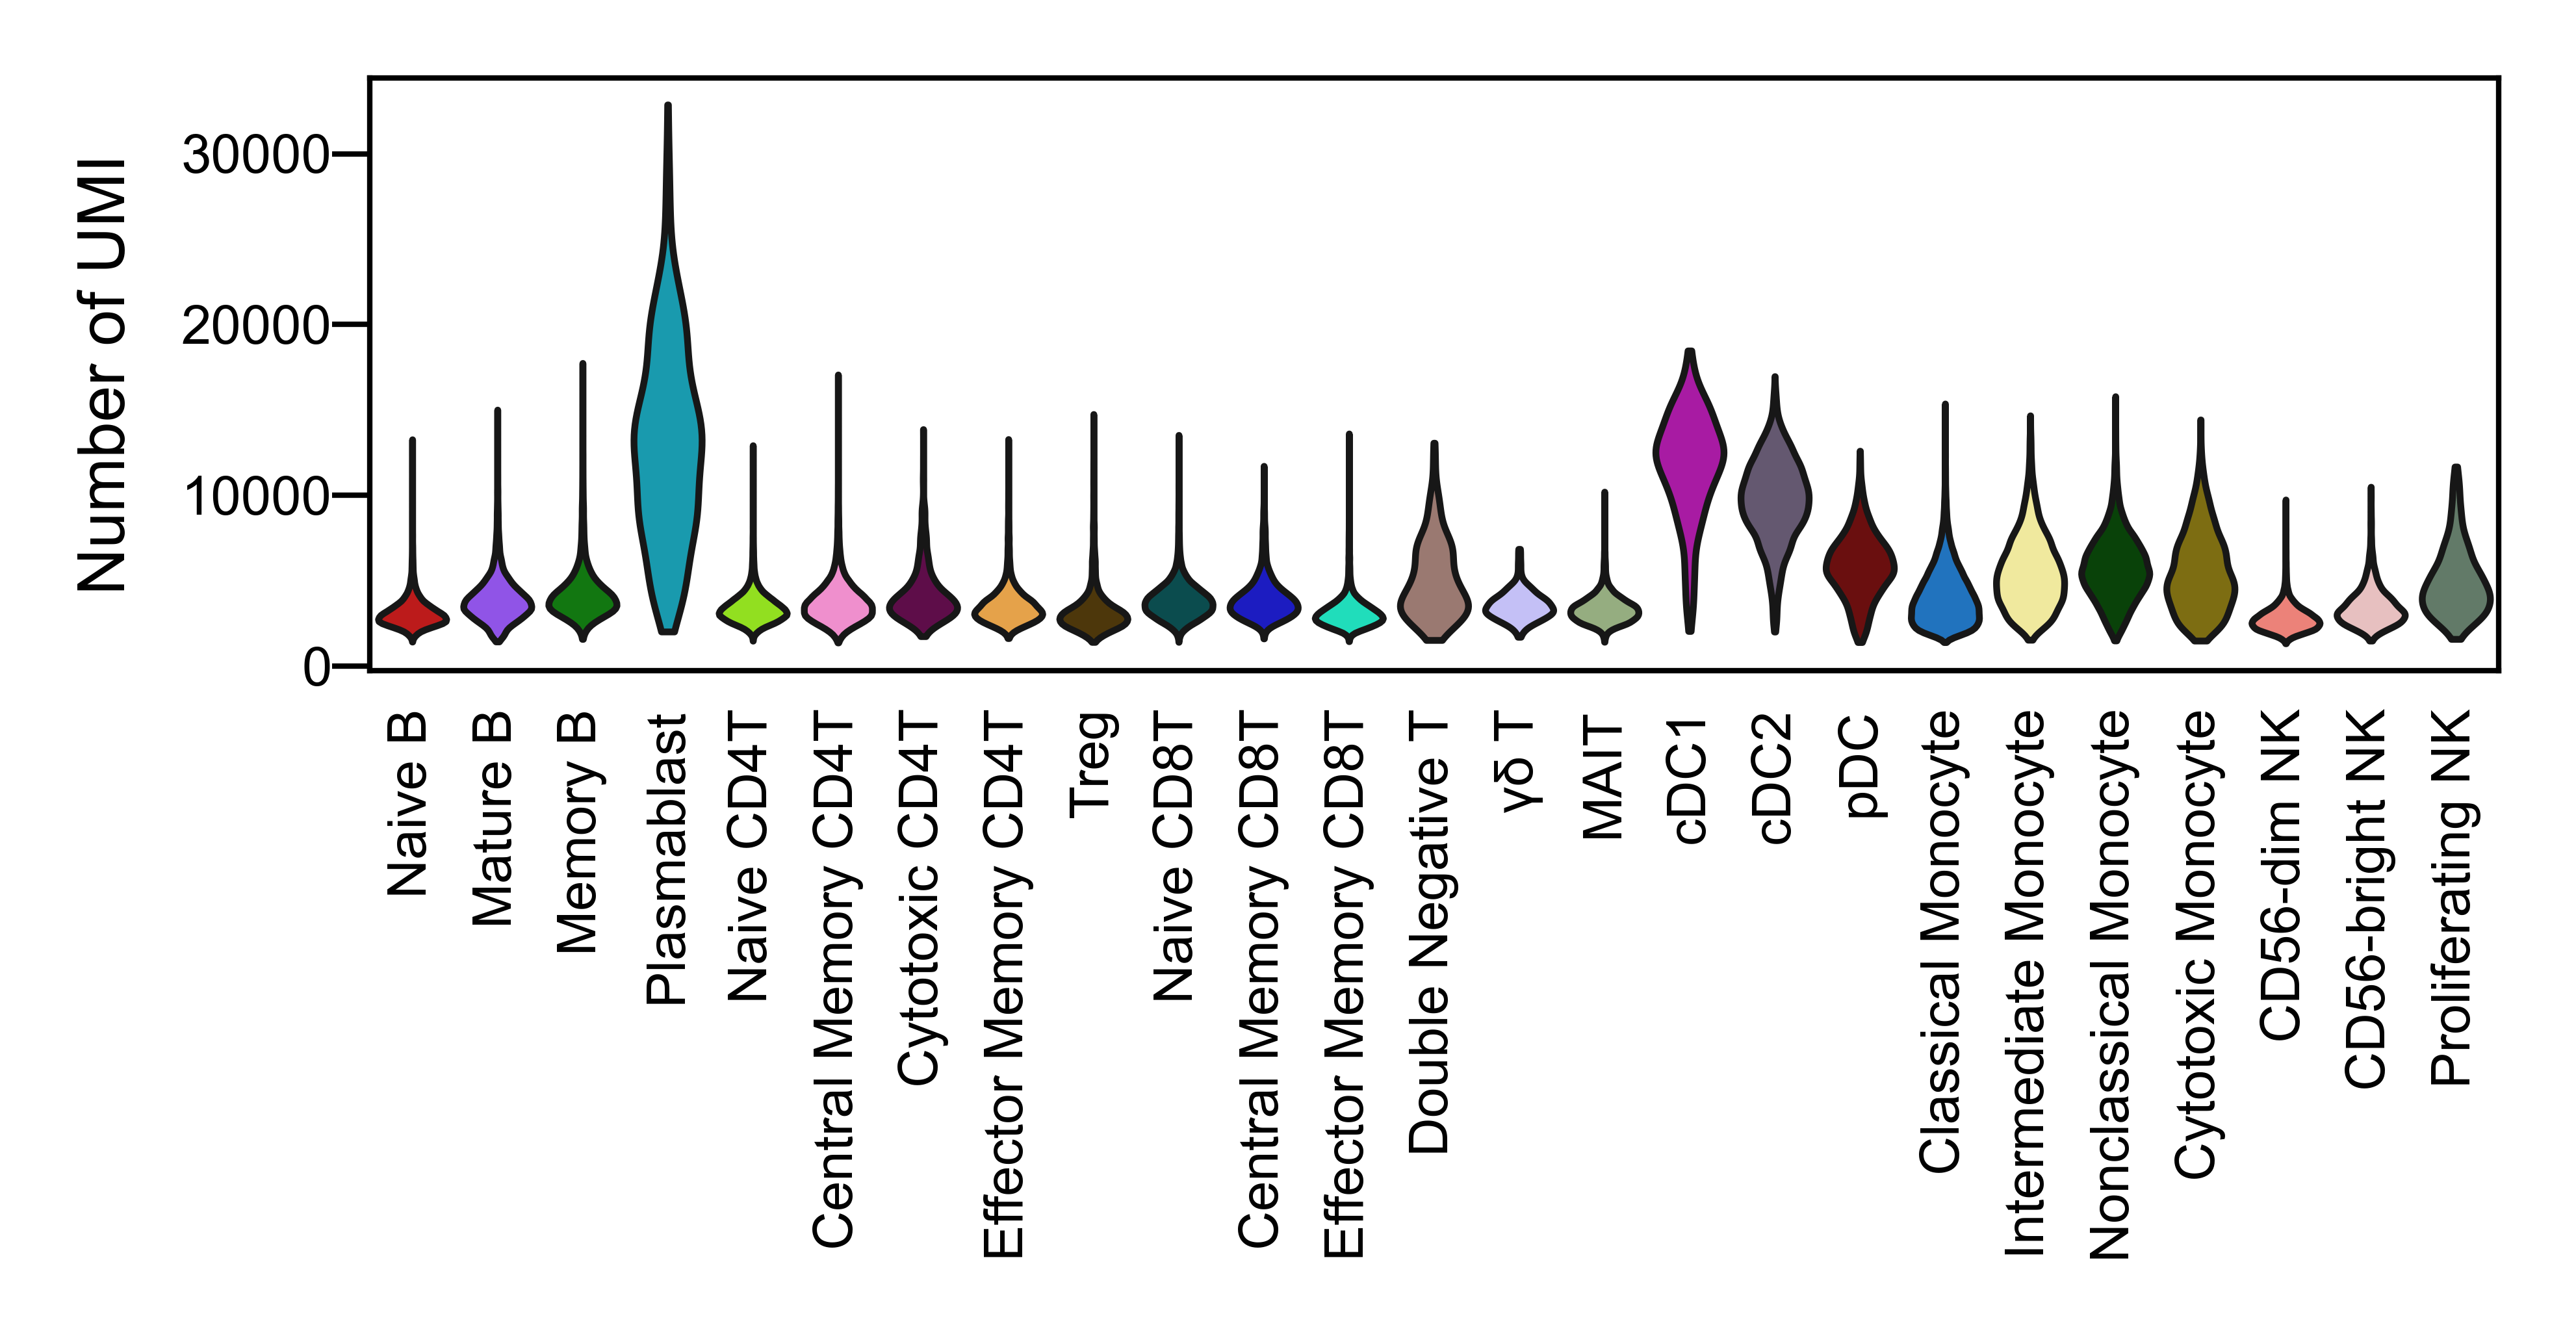

In [74]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['nCount_RNA'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Number of UMI',
    rotation=90,
    ax=ax,
    save='qc_NumUMI.svg'
)


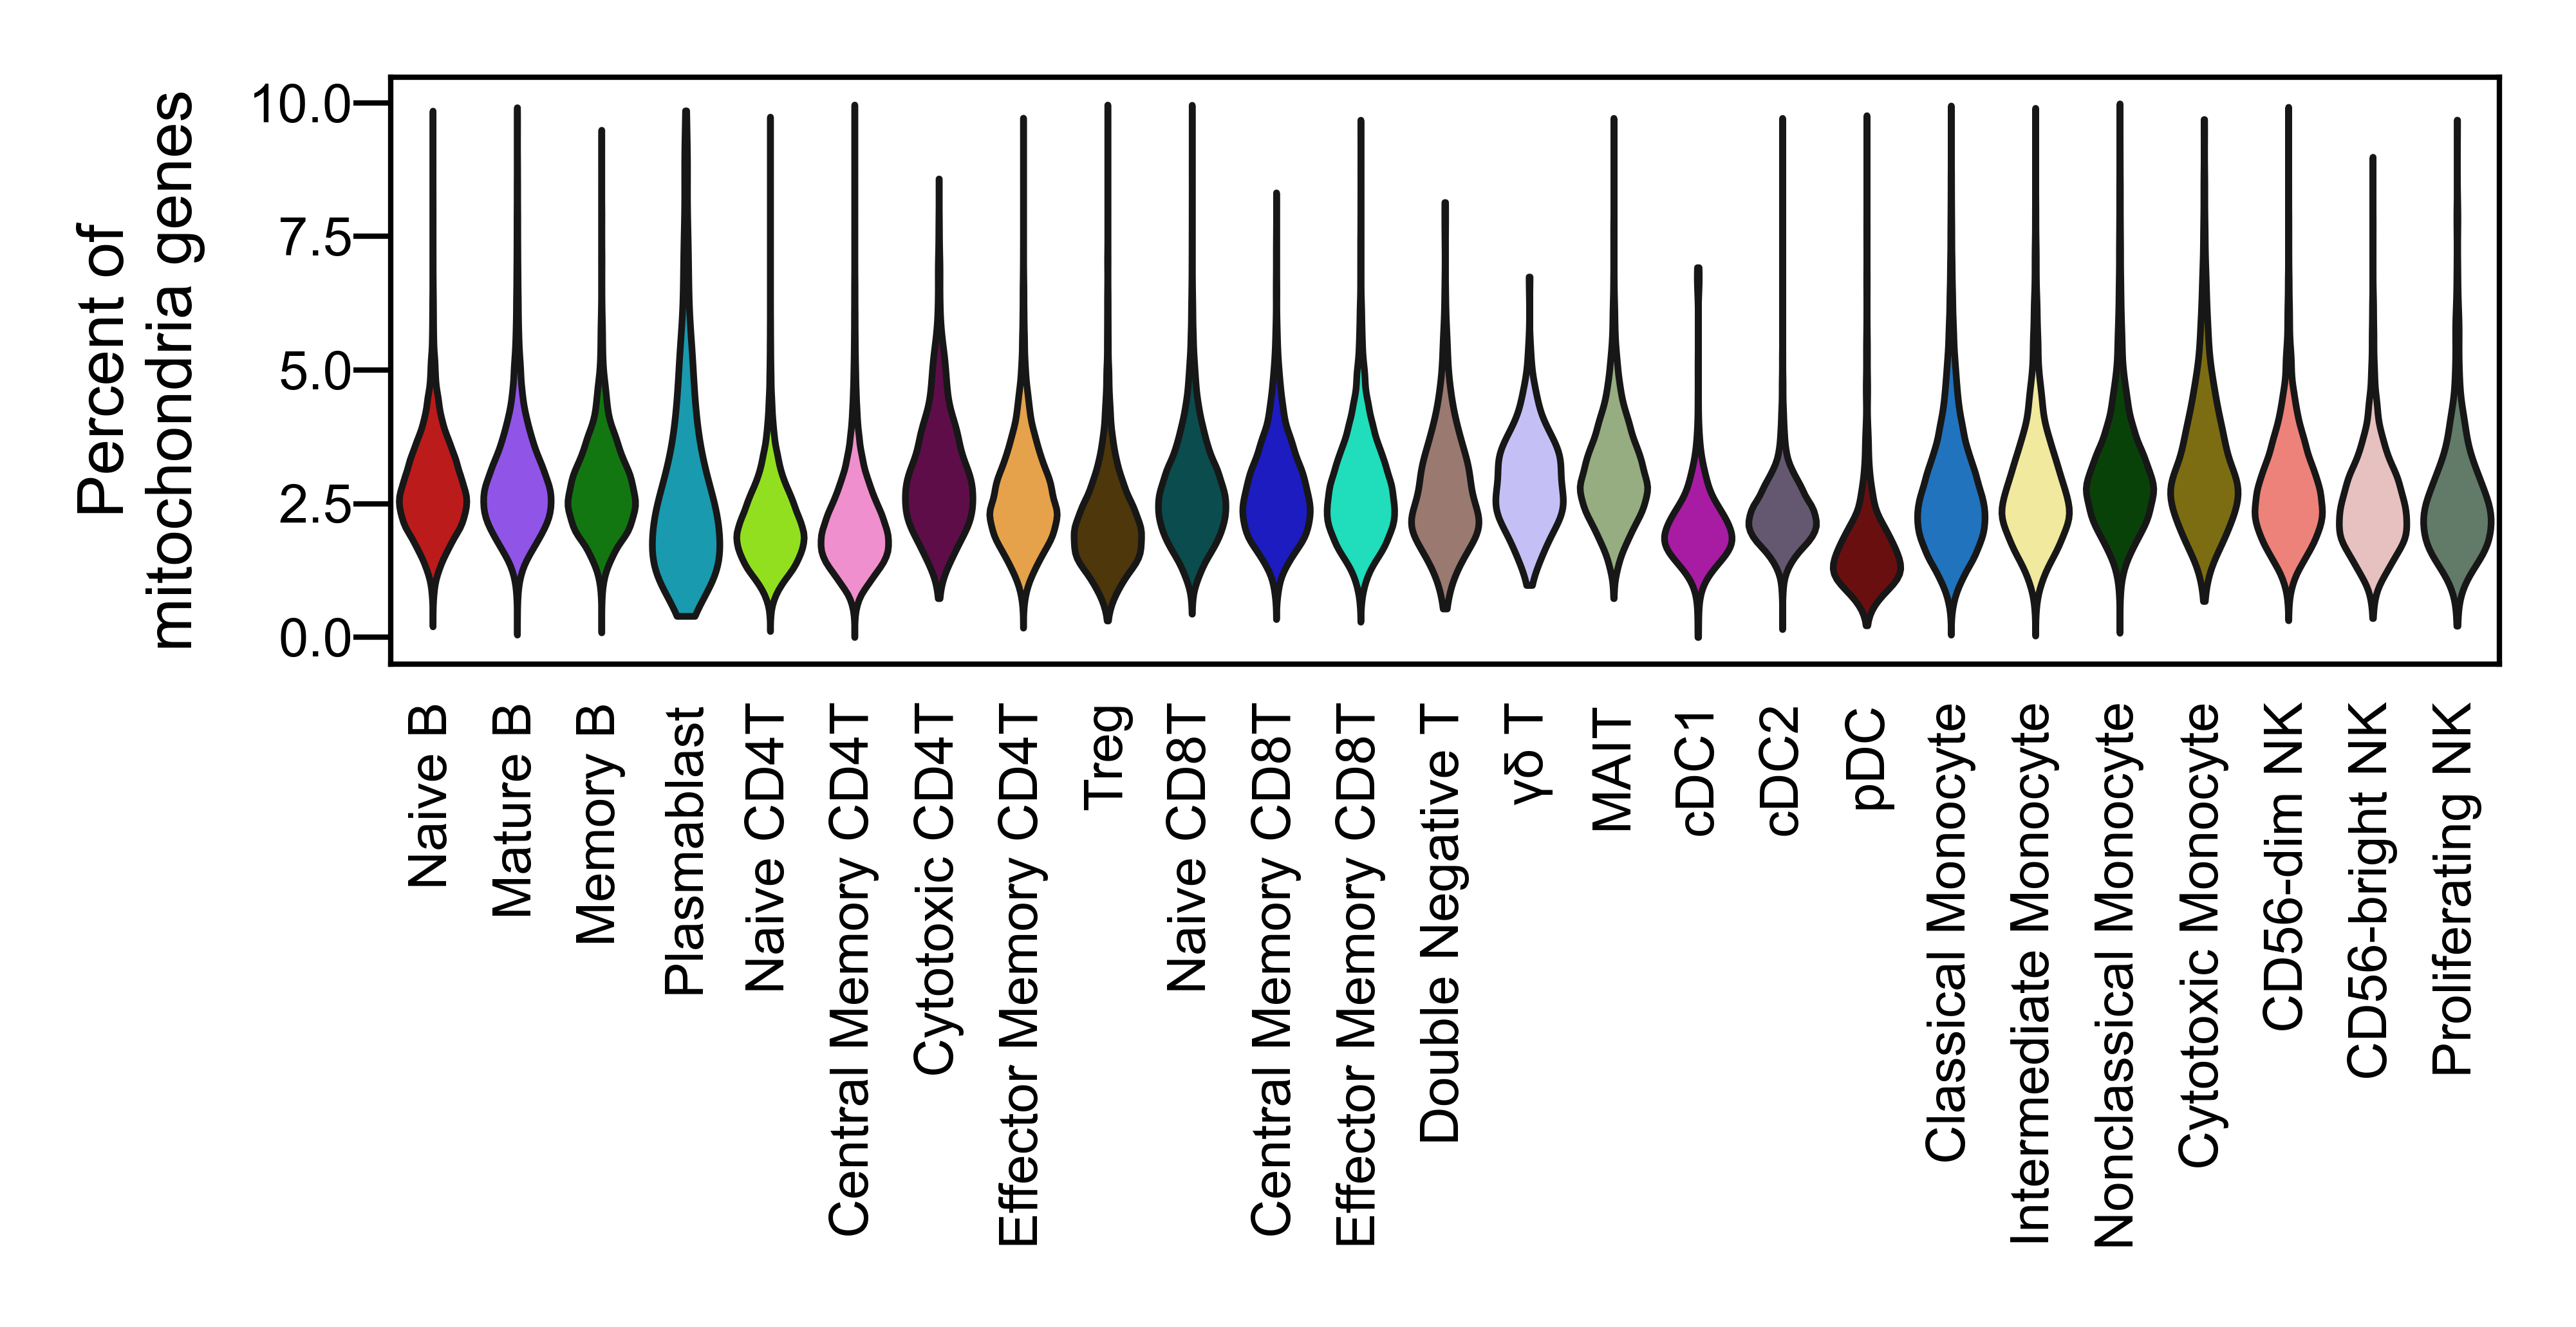

In [75]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['percent.mt'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Percent of\nmitochondria genes',
    rotation=90,
    ax=ax,
    save='qc_Mtpct.svg'
)


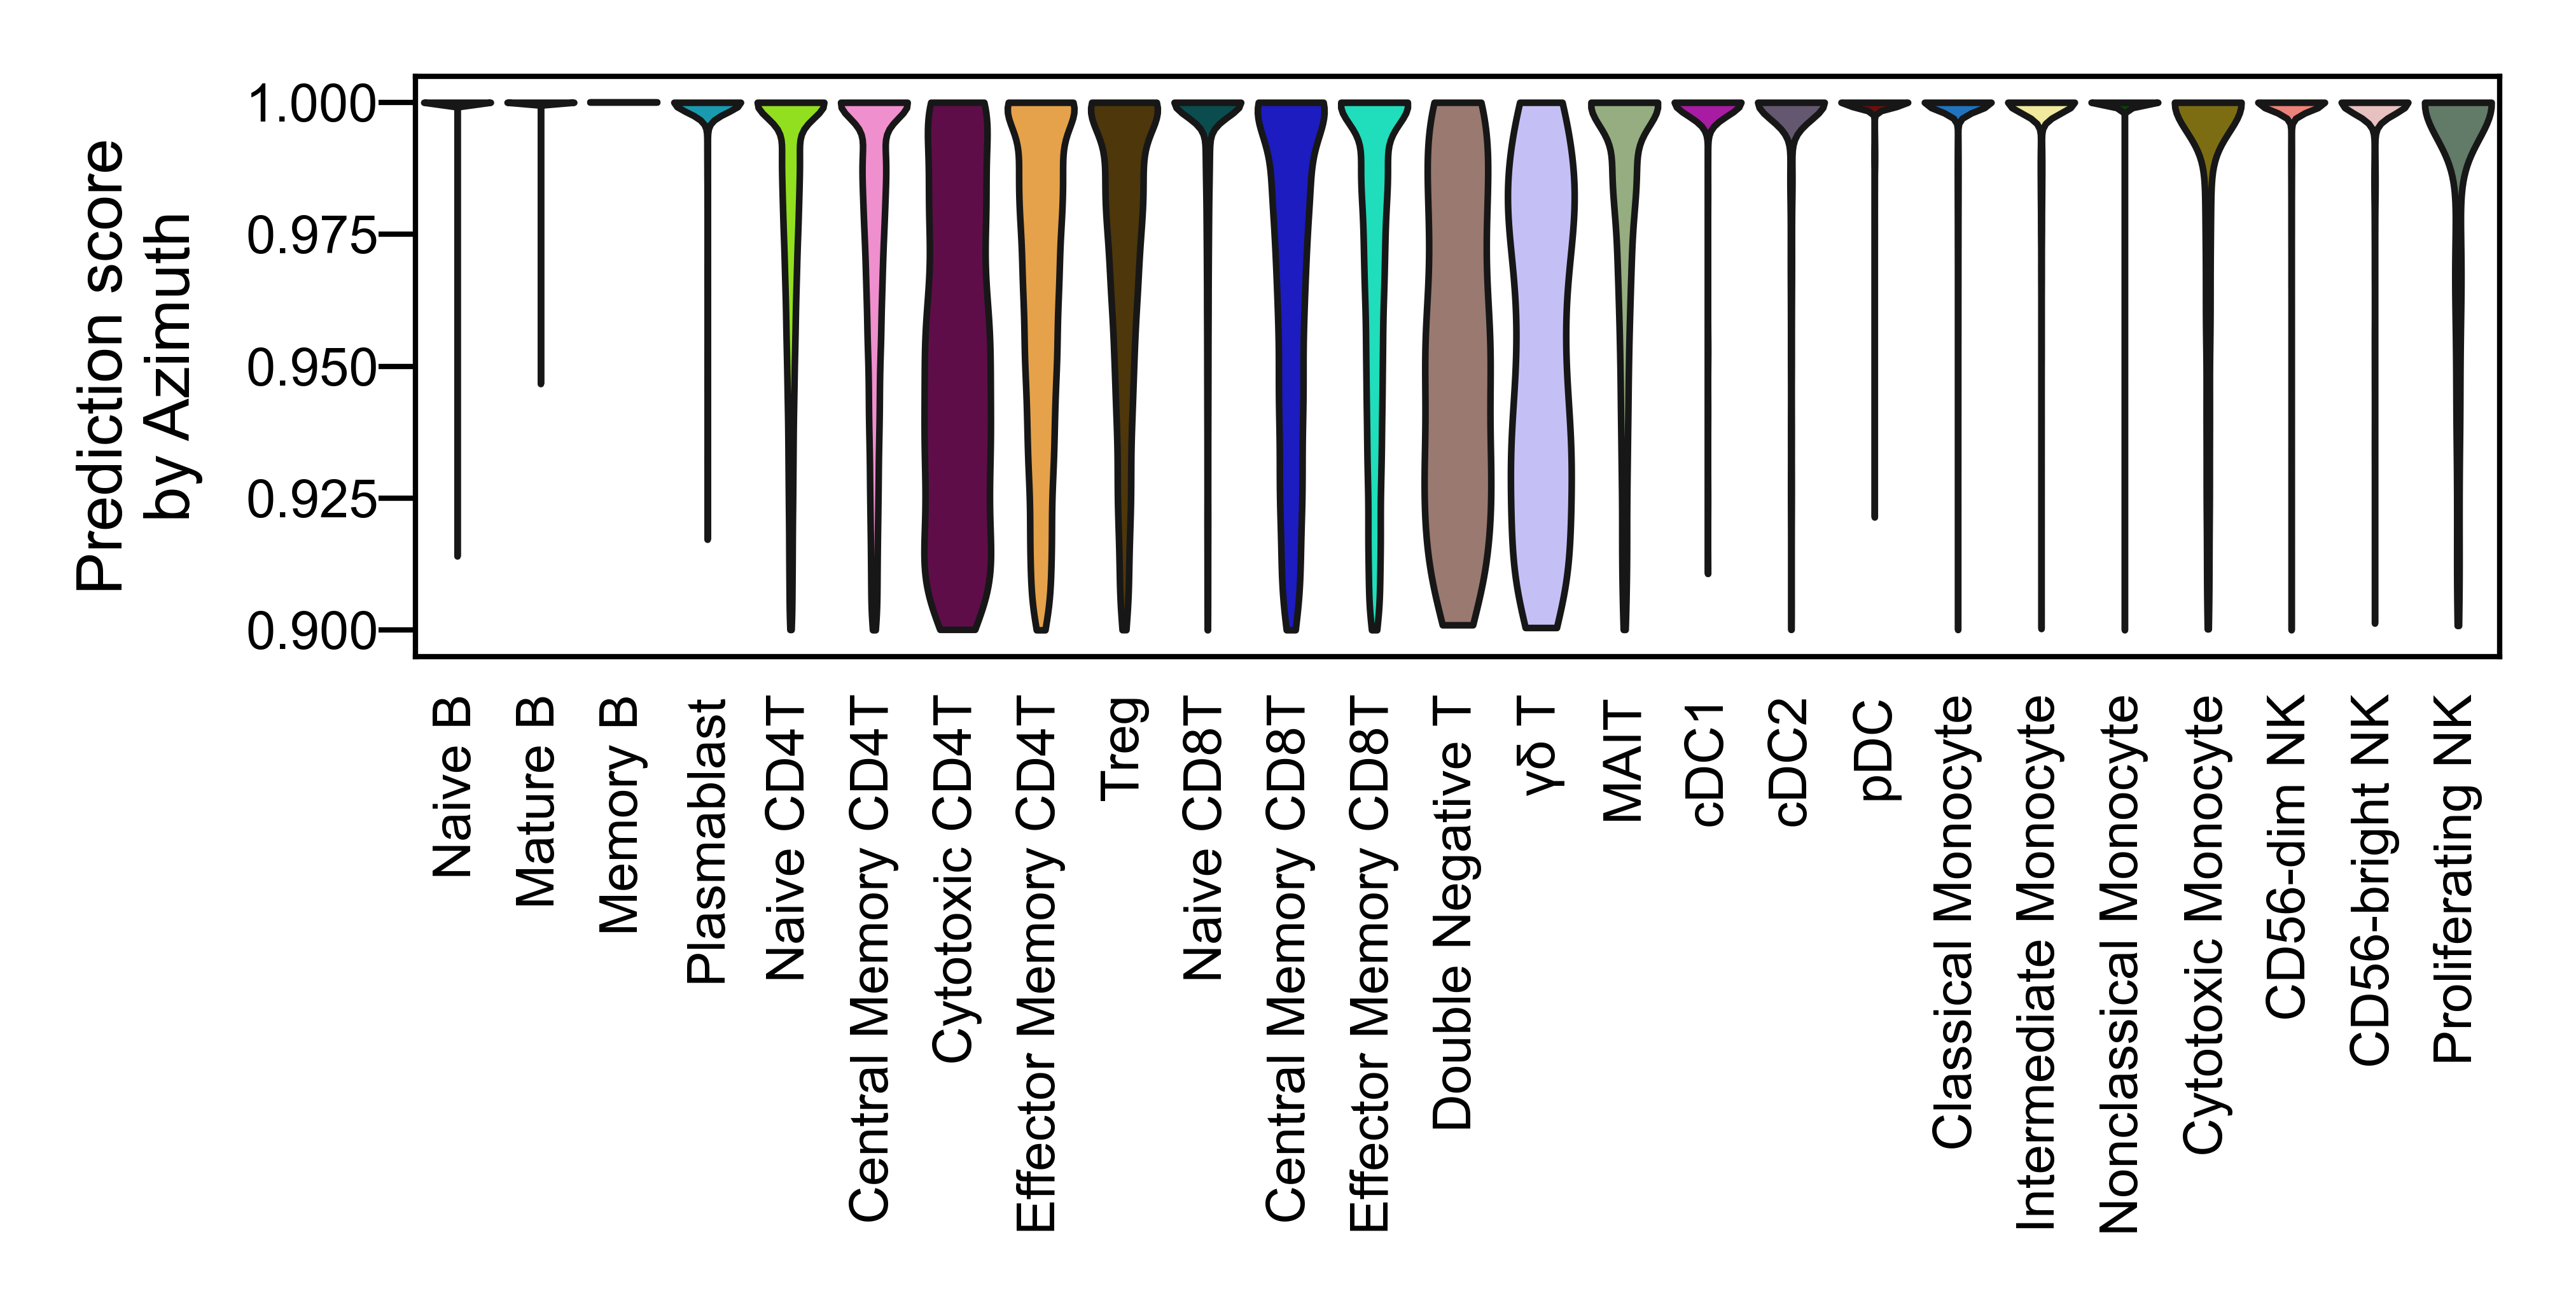

In [76]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['predicted.celltype.l1.score'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Prediction score\nby Azimuth',
    rotation=90,
    ax=ax,
    save='qc_azimuthScoreL1.svg'
)


# Key protein markers

In [35]:
impadt = pd.read_csv('data/03_cleandata/ft_all_impADT.csv', index_col=0)

impadt.columns = [f'impADT-{x}' for x in impadt.columns]
impadt

,impADT-CD39,impADT-Rat-IgG1-1,impADT-CD107a,impADT-CD62P,impADT-TCR-2,impADT-CD30,impADT-CD31,impADT-CD34,impADT-CD35,impADT-CD36,...,impADT-CD169,impADT-CD28,impADT-CD161,impADT-CD163,impADT-CD138-1,impADT-CD164,impADT-CD138-2,impADT-CD144,impADT-CD202b,impADT-CD11c
Pool137_10_AAACCTGAGACTCGGA-1,0.534771,0.785664,1.065888,2.486620,1.455330,0.288762,2.010069,0.543328,2.193929,0.091107,...,0.178707,2.075897,0.157420,0.395004,0.746080,0.266822,0.714414,0.703357,0.794421,0.816402
Pool137_10_AAACCTGAGATCTGCT-1,1.449415,0.667198,1.409613,3.622773,0.756409,0.276608,3.843209,0.701777,2.597695,0.575529,...,0.435918,1.027539,0.154405,0.470037,0.452024,0.488064,0.660572,0.507108,0.594781,1.957562
Pool137_10_AAACCTGAGATTACCC-1,0.452265,0.744363,0.950950,2.527489,1.274952,0.350221,2.292906,0.577347,2.148938,0.111531,...,0.235422,1.921119,0.193224,0.305376,0.644874,0.308330,0.638812,0.708355,0.717815,0.808716
Pool137_10_AAACCTGAGCTGCGAA-1,0.457184,0.743687,1.007076,2.489951,1.504251,0.353372,1.928150,0.587430,2.122775,0.118000,...,0.216452,2.083942,0.217496,0.381886,0.581419,0.211308,0.686135,0.668243,0.729290,0.903699
Pool137_10_AAACCTGAGGACACCA-1,1.333606,0.514865,1.641695,3.931263,0.728445,0.187504,3.775454,0.703609,2.658446,0.691417,...,0.397310,0.917504,0.166297,0.450487,0.386663,0.559608,0.630211,0.501299,0.550563,2.138054
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1.282291,0.748149,1.338984,3.064777,0.747717,0.329519,3.144872,0.701284,4.059995,0.752640,...,0.609118,1.075461,0.181407,0.460948,0.656513,0.366761,0.802404,0.660312,0.745983,1.922274
Pool138_9_TTTGTCATCCTAGGGC-1,0.349624,0.709147,1.003383,2.520453,1.337860,0.178123,1.757185,0.553130,2.815921,0.133724,...,0.328057,2.326010,0.310319,0.388375,0.594377,0.282331,0.778680,0.771170,0.787437,0.856449
Pool138_9_TTTGTCATCGCACTCT-1,0.486551,0.747766,0.945113,2.519550,1.570202,0.306416,1.920877,0.571780,2.120506,0.148358,...,0.197388,2.130674,0.197334,0.373094,0.584165,0.265373,0.665075,0.731853,0.697750,0.870280
Pool138_9_TTTGTCATCTAACTGG-1,0.403886,0.751390,0.949030,2.523064,1.383994,0.272842,1.826066,0.540308,2.226121,0.136343,...,0.200529,2.248959,0.250389,0.354785,0.599786,0.308921,0.601553,0.735475,0.807407,0.818152


In [36]:
dat.obs.head(3)

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,Phase,celltype_level3,sampleid,batch,group,race,age,diabetes,obesity,race_stage
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,G1,Naive CD4T,1-H,1,HRL,NHW,62.3,N,N,NHW-HRL
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,S,Nonclassical Monocyte,1-H,1,HRL,NHW,62.3,N,N,NHW-HRL
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,S,Naive CD8T,1-H,1,HRL,NHW,62.3,N,N,NHW-HRL


In [37]:
# Example: Ensure the impadt index is of string type to match dat.obs_names
impadt.index = impadt.index.astype(str)
dat.obs.index = dat.obs.index.astype(str)

# Subset impadt to only cells in dat
impadt_sub = impadt.loc[dat.obs_names.intersection(impadt.index)]

# Make sure order matches dat.obs_names
impadt_sub = impadt_sub.reindex(dat.obs_names)

# Add as obs columns (will add each protein as a new column in .obs)
dat.obs = pd.concat([dat.obs, impadt_sub], axis=1)

# Now each protein marker is accessible via dat.obs['CD19'], dat.obs['CD20'], etc.

In [38]:
# Panel/grid setup

channels = [
    'CD19','CD20','CD21','CD22','CD38-1',
    'CD3-1','CD4-1','CD8','TCR-V-2','CD161',
    'CD1c','CD141','CD123','CD303','CD304',
    'CD64','CD14','CD16','CD335','CD56-1'
]
ncols = 5
nrows = int(np.ceil(len(channels) / ncols))
panel_width = 2   # inches per plot (adjust as needed)
panel_height = 2  # inches per plot
figsize = (panel_width * ncols, panel_height * nrows)
sc.set_figure_params(figsize=figsize)

major_celltype_palette = {
    'B':    'Blues',
    'T':    'Oranges',
    'DC':   'Greens',
    'Mono': 'Reds',
    'NK':   'Purples',
}
channel2celltype = {
    'CD19': 'B', 'CD20': 'B', 'CD21': 'B', 'CD22': 'B', 'CD38-1': 'B',
    'CD3-1': 'T', 'CD4-1': 'T', 'CD8': 'T', 'TCR-V-2': 'T', 'CD161': 'T',
    'CD1c': 'DC', 'CD141': 'DC', 'CD123': 'DC', 'CD303': 'DC', 'CD304': 'DC',
    'CD64': 'Mono', 'CD14': 'Mono',
    'CD16': 'NK', 'CD335': 'NK', 'CD56-1': 'NK'
}

fig, axs = plt.subplots(figsize=figsize, 
                        ncols=ncols, nrows=nrows,
                        gridspec_kw={'wspace': 0.3, 'hspace': 0.3}  # <-- increased spacing
                       )
axs = axs.flatten()

for idx, ch in enumerate(channels):
    ax = axs[idx]
    sc.pl.umap(
        dat,
        color=f'impADT-{ch}',
        show=False,
        title=ch,  # Just the channel name for the subplot
        legend_loc=None,  # Hide legend, show colorbar   
        frameon=False,
        cmap=major_celltype_palette[channel2celltype[ch]],
        ax=ax
    )
    ax.tick_params(axis='both', labelsize=6, pad=0)
    ax.title.set_fontsize(15)

# ---- ADJUST COLORBAR FONT SIZES ----
for child_ax in fig.axes:
    if hasattr(child_ax, 'get_ylabel') and child_ax.get_ylabel() != '':
        child_ax.tick_params(labelsize=5)
        child_ax.yaxis.label.set_size(5)
        # For horizontal colorbars, use: child_ax.xaxis.label.set_size(5)

fig.savefig('plots/FigureS1/impADT_mainCelltypes.svg', bbox_inches='tight', dpi=600)
plt.close(fig)

# Major cell type color legend

/tmp/ipykernel_4003074/4074073658.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = cm.get_cmap(palette[lab])(cmap_pos)


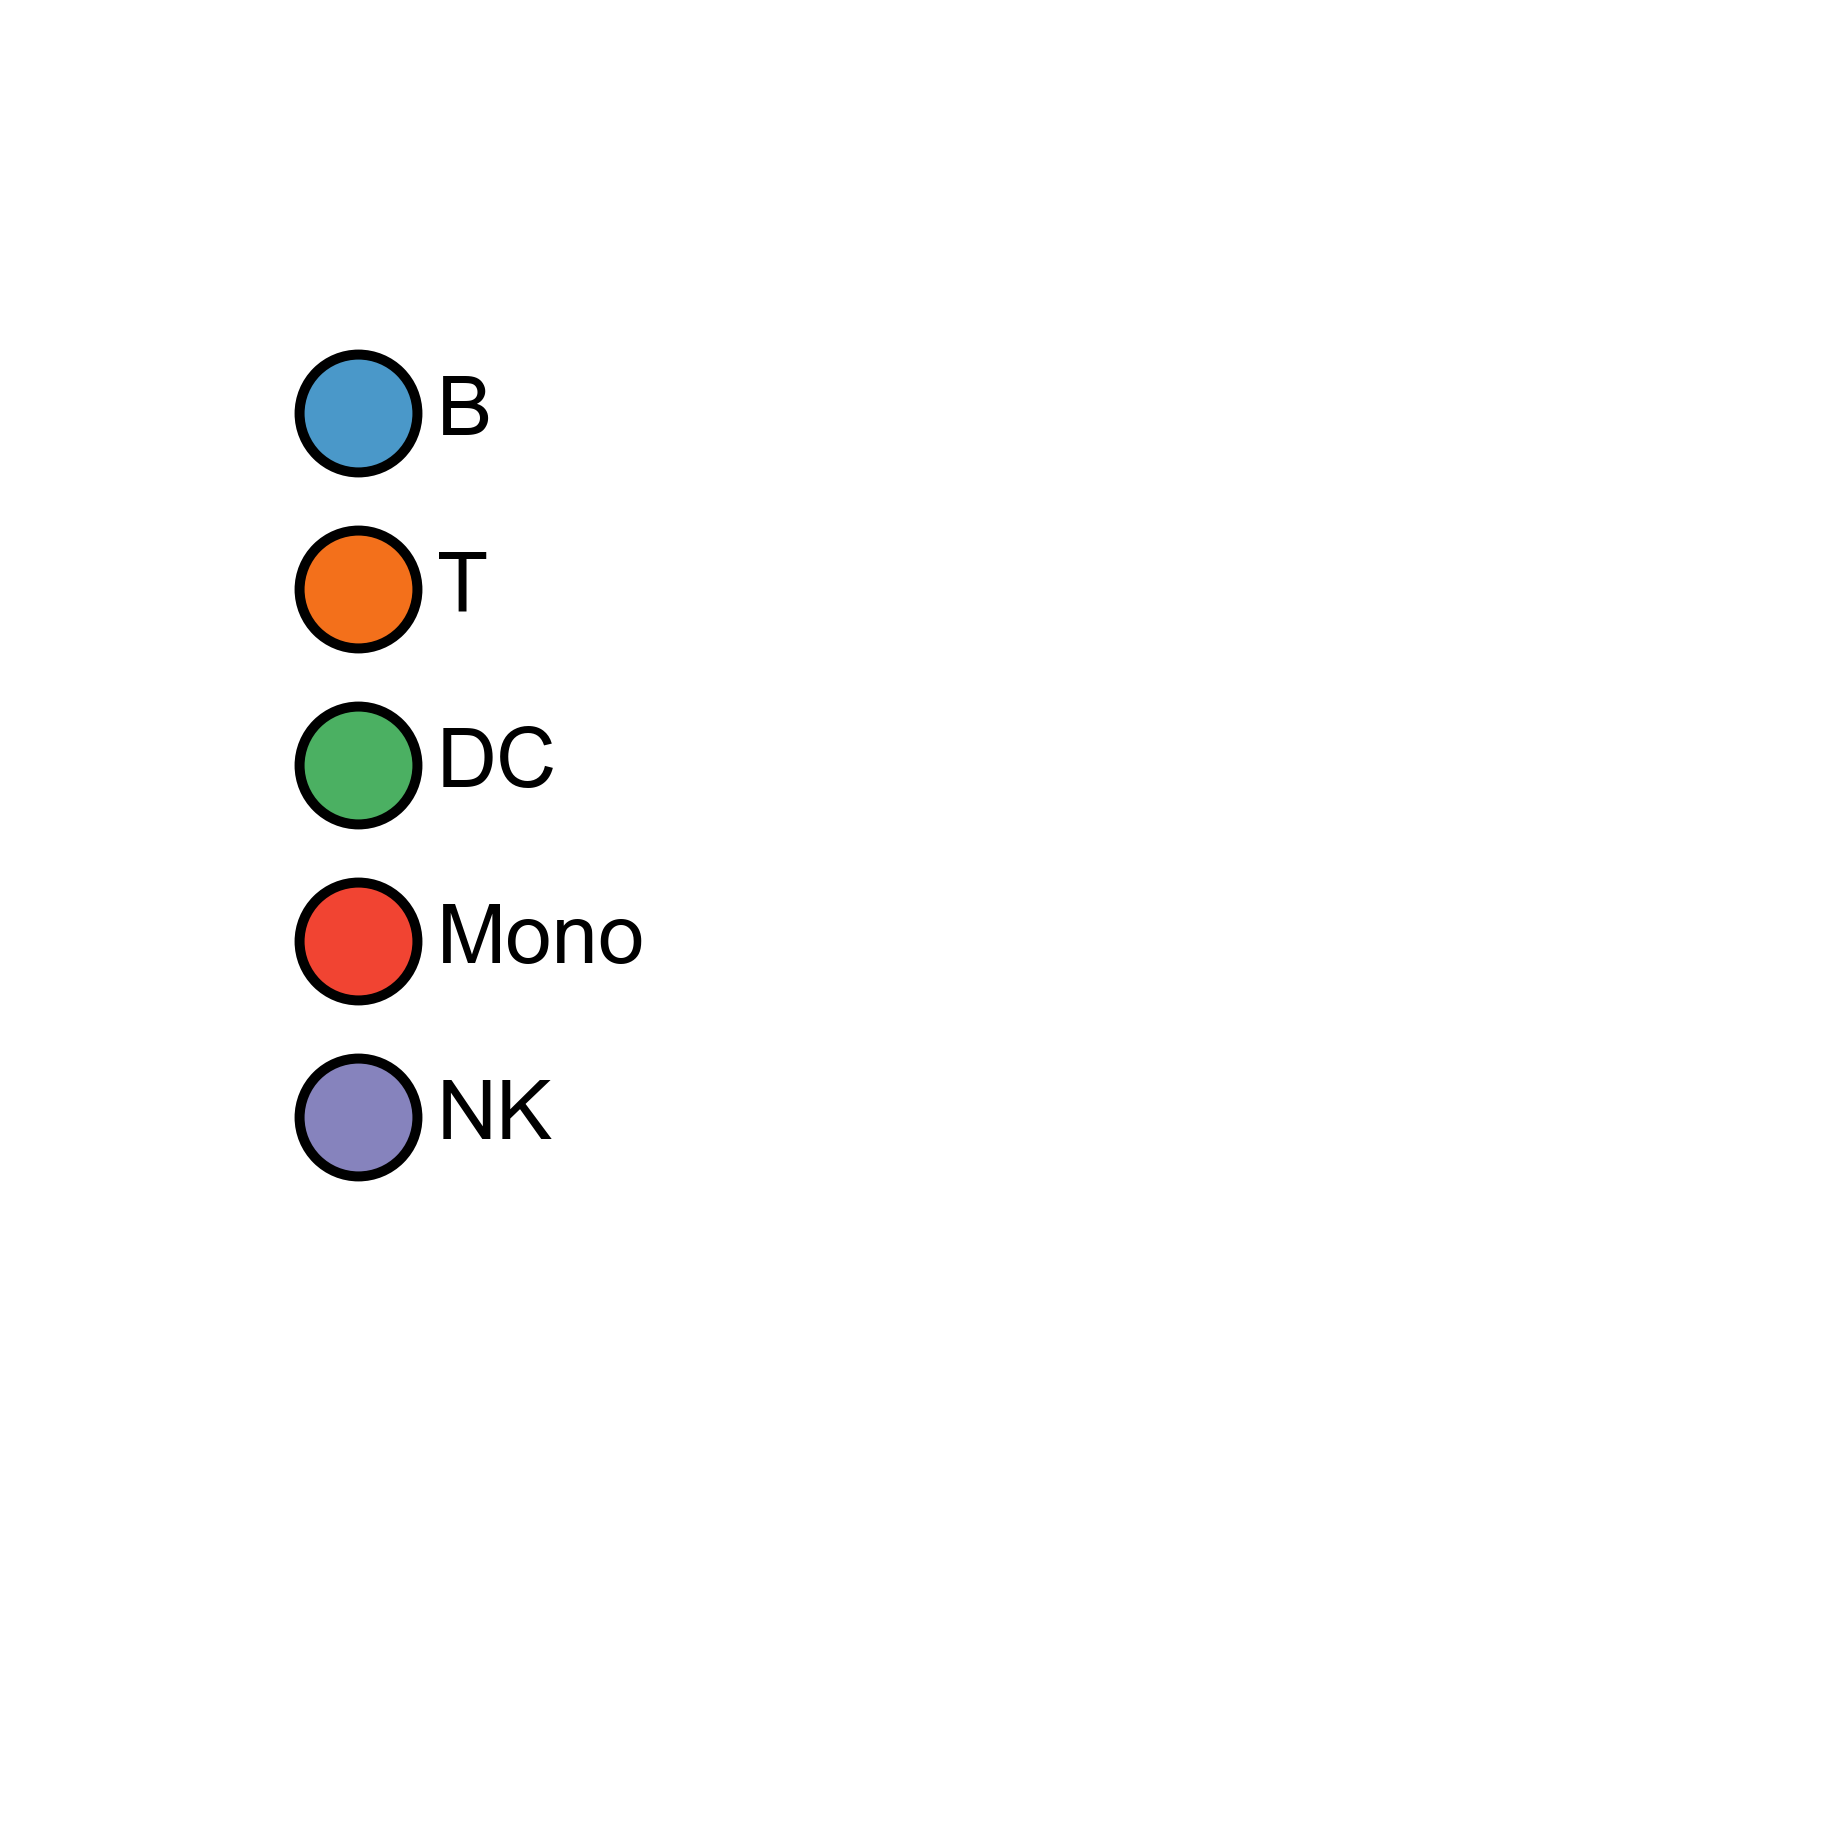

In [20]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

major_celltype_palette = {
    'B':    'Blues',
    'T':    'Oranges',
    'DC':   'Greens',
    'Mono': 'Reds',
    'NK':   'Purples',
}

def legend_column(palette, filename="major_celltype_legend.svg",
                  dot_size=50, font_size=5, cmap_pos=0.6, gap=0.1, step=0.3):
    """
    One row per cell type (vertical legend).
    """
    labels = list(palette.keys())
    n = len(labels)

    # Figure height tuned to number of entries
    fig_w = 1.5
    fig_h = n * step
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    x = 0.3  # left margin
    y0 = 0.8  # starting top position
    for i, lab in enumerate(labels):
        y = y0 + (n - 1 - i) * step  # plot from top to bottom
        color = cm.get_cmap(palette[lab])(cmap_pos)

        # dot
        ax.scatter([x], [y], s=dot_size, c=[color], edgecolor='black', linewidth=0.6)

        # text to the right
        ax.text(x + gap, y, lab, va='center', ha='left', fontsize=font_size)

    # tidy like a legend
    ax.set_xlim(0, 2)
    ax.set_ylim(-0.2, y0 + (n - 1) * step + 0.5)
    ax.axis('off')

    plt.tight_layout()
    plt.savefig(filename, format="svg")
    plt.show()

# run
legend_column(major_celltype_palette, filename="plots/LegendShared/major_celltype_palette.svg")